# Exercicio 2 - GAN convolucional no MNIST

Objetivo: escolher uma base de imagens e treinar uma GAN com gerador baseado em operacoes convolucionais. A base escolhida foi o MNIST, composto por imagens em escala de cinza de digitos manuscritos, com tamanho original 28 x 28 e 10 classes.

O experimento compara dois criterios de parada:

1. numero fixo de epocas;
2. parada antecipada quando a metrica FID-pixel para de melhorar.

Tambem sao usadas duas medidas de qualidade de imagem para analisar o resultado da GAN:

1. FID-pixel sobre representacoes 7 x 7 obtidas por average pooling;
2. MMD com kernel RBF sobre as mesmas representacoes.


## Descricao da implementacao

Linguagem e bibliotecas: Python com PyTorch, torchvision, NumPy e Matplotlib.

Preparacao dos dados: as imagens do MNIST sao convertidas para tensores e normalizadas de [0, 1] para [-1, 1], pois a ultima camada do gerador usa `tanh`. A normalizacao aplicada e:

$$x_{norm} = 2x - 1.$$

Desbalanceamento: o MNIST e aproximadamente balanceado entre as 10 classes. A celula de inspecao abaixo calcula e mostra a contagem por classe. Como a GAN deste exercicio e nao condicional, os rotulos nao entram no treinamento, mas a distribuicao de classes ajuda a interpretar a diversidade das imagens geradas.

Aumento de dados: nao foi usado aumento de dados. Para o MNIST, translacoes ou rotacoes agressivas poderiam alterar a identidade visual de alguns digitos e dificultar a avaliacao direta da distribuicao original.

Inicializacao: pesos convolucionais inicializados por distribuicao normal com media 0 e desvio padrao 0.02, pratica comum em DCGAN. Camadas de batch normalization usam pesos com media 1 e desvio padrao 0.02 e vies zero.

Ativacoes: o gerador usa ReLU nas camadas intermediarias e `tanh` na saida. O discriminador usa LeakyReLU com inclinacao 0.2.

Funcao de perda: foi usada entropia cruzada binaria com logits (`BCEWithLogitsLoss`). Para um exemplo com rotulo $y \in \{0,1\}$ e logit $s$, a perda e:

$$\mathcal{L}(s,y) = -y\log(\sigma(s)) - (1-y)\log(1-\sigma(s)).$$

Otimizador: Adam para gerador e discriminador, com `lr=2e-4`, `betas=(0.5, 0.999)`. Esses valores seguem a configuracao classica da DCGAN e tendem a estabilizar o jogo adversarial.

Regularizacao: foi usado batch normalization no gerador e no discriminador, exceto na saida. Nao foi usado dropout nem penalizacao extra na funcao de perda, para manter a comparacao entre criterios de parada isolada.

Hiperparametros: foram definidos manualmente com base em configuracoes padrao de DCGAN, nao por busca automatica.

### Bibliotecas:

In [6]:
from copy import deepcopy
from pathlib import Path
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

### Carregando Dataset MNIST

In [12]:
DATA_DIR = Path('data')
BATCH_SIZE = 128
VAL_FRACTION = 0.1  # 10% dos dados de treino reservados para validação

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

mnist_full = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)

n_val = int(len(mnist_full) * VAL_FRACTION)
n_train = len(mnist_full) - n_val

mnist_train, mnist_val = torch.utils.data.random_split(
    mnist_full,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED),
)

loader = DataLoader(
    mnist_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True,
)

val_loader = DataLoader(
    mnist_val,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
    drop_last=True,
)

len(loader.dataset), len(loader), len(val_loader.dataset), len(val_loader)

(54000, 421, 6000, 46)

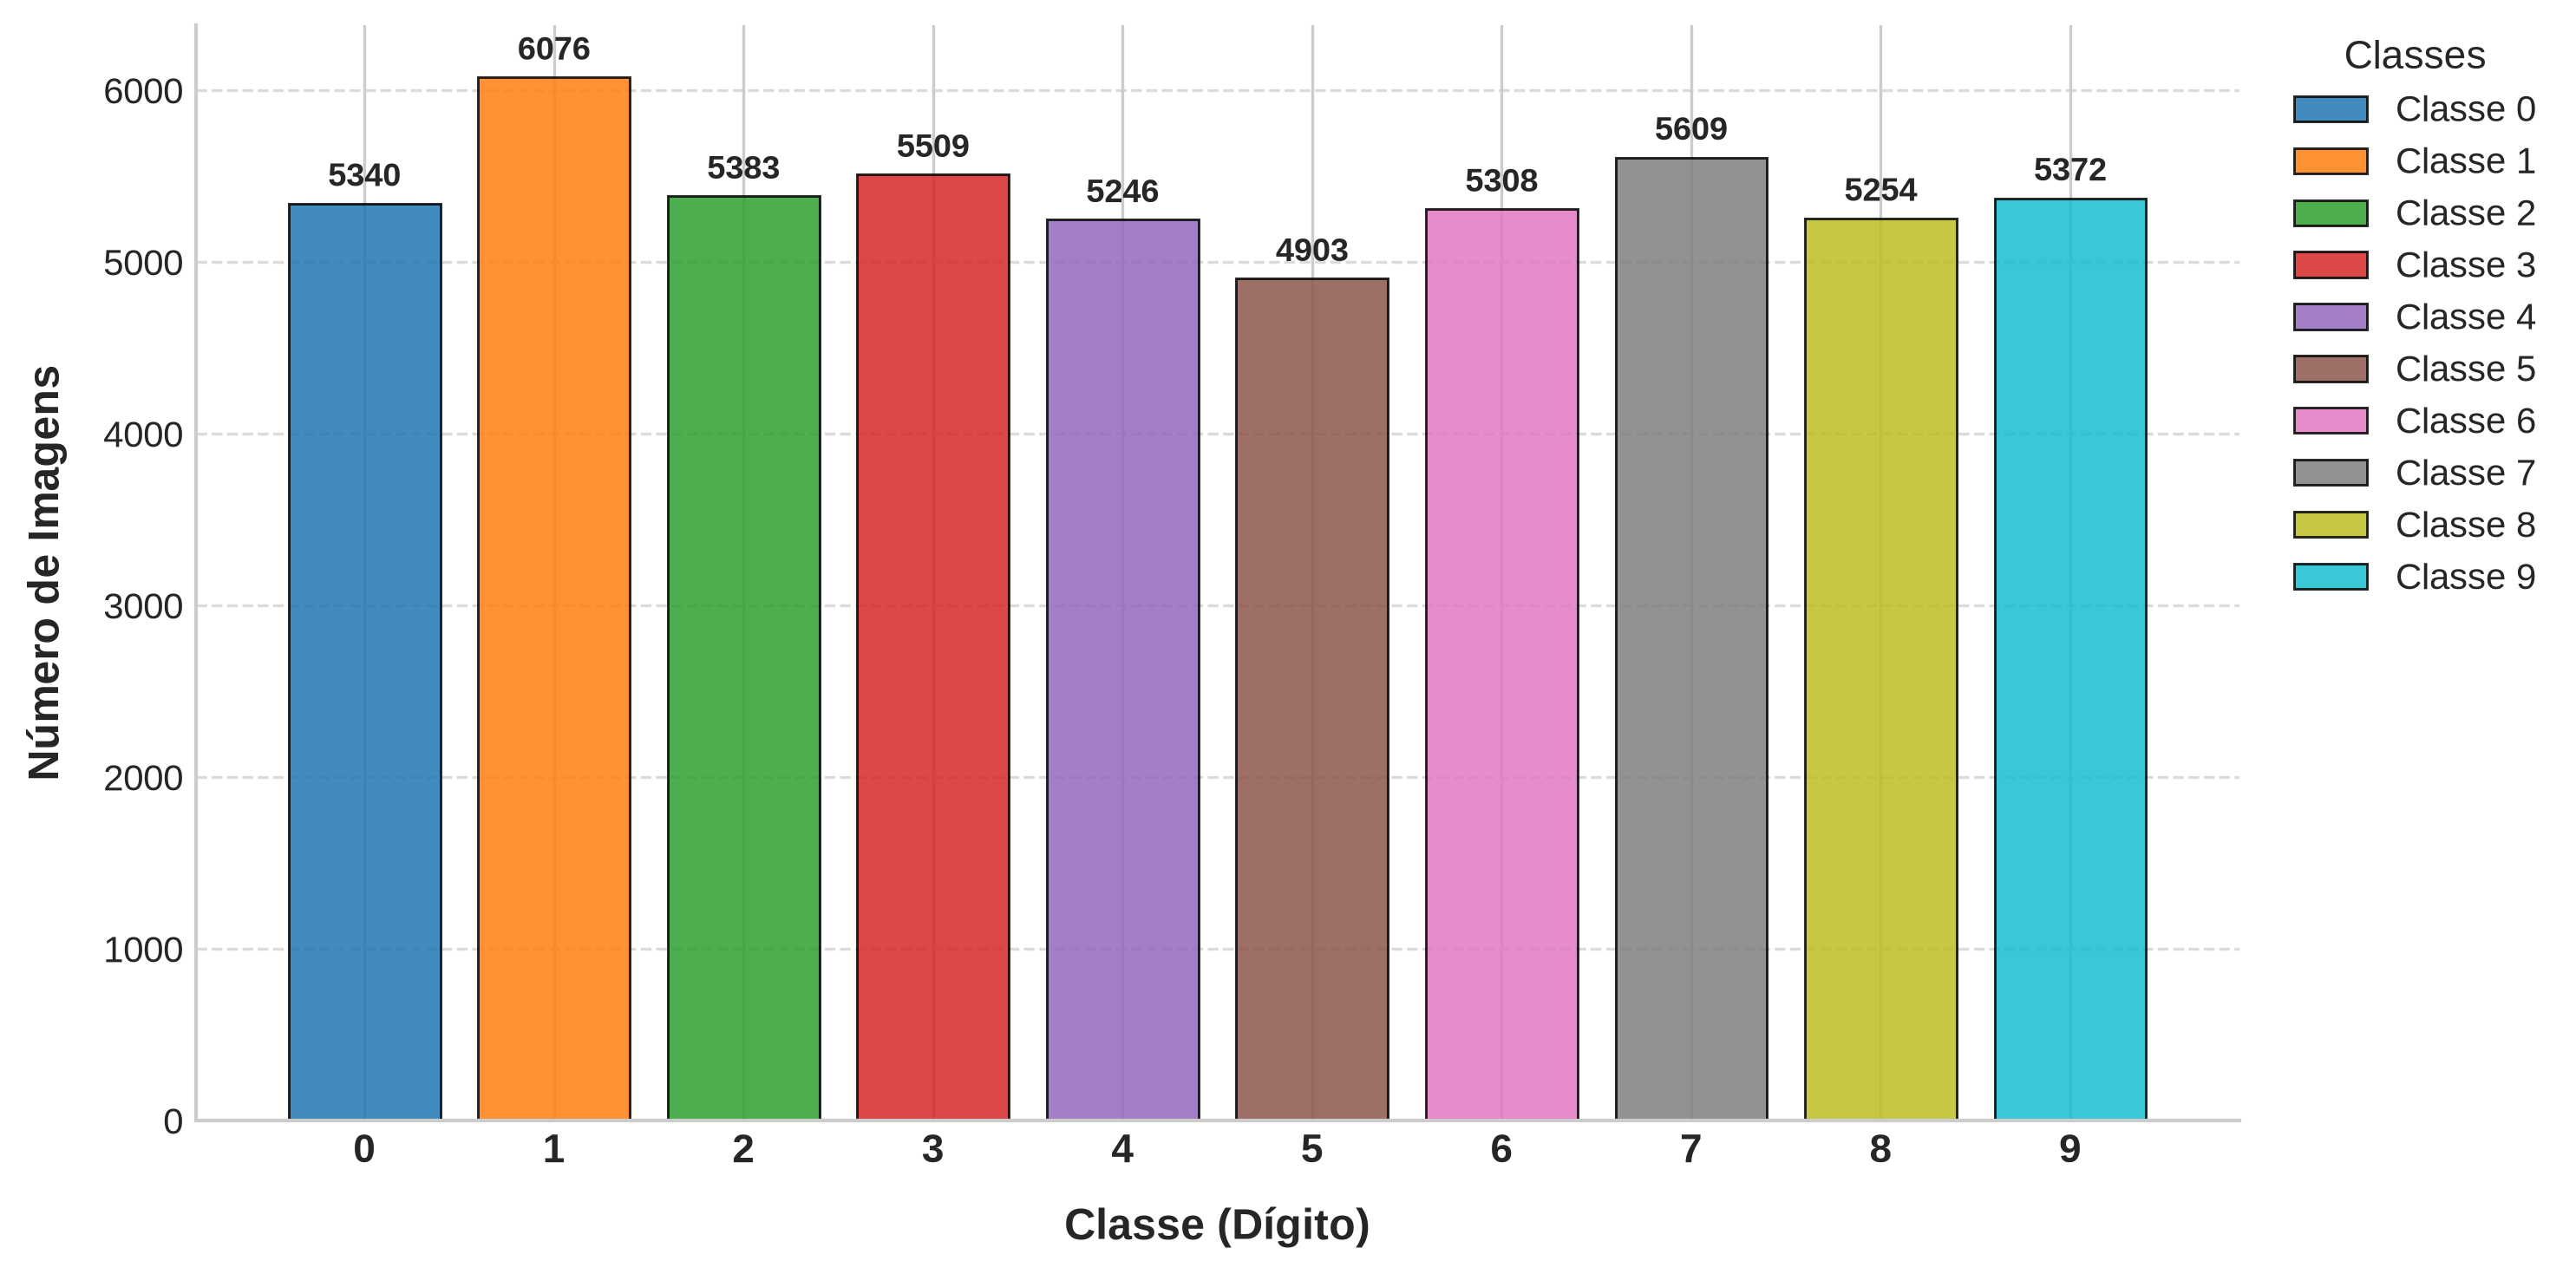

array([5340, 6076, 5383, 5509, 5246, 4903, 5308, 5609, 5254, 5372])

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import Subset

# --- Seu código de processamento de dados (mantido igual) ---
targets = mnist_train.dataset.targets if isinstance(mnist_train, Subset) else mnist_train.targets
if isinstance(mnist_train, Subset):
    targets = targets[mnist_train.indices]
counts = torch.bincount(targets, minlength=10).cpu().numpy()

# --- Configuração e Estilização do Gráfico ---

# Definindo um estilo base limpo (se disponível)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Usamos subplots para melhor controle de layout e resolução (dpi)
fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

# Mapeando 10 cores distintas usando o colormap 'tab10'
colors = plt.cm.tab10(np.arange(10))

# Criando as barras coloridas com bordas finas e uma leve transparência
bars = ax.bar(range(10), counts, color=colors, edgecolor='black', linewidth=0.7, alpha=0.85)

# Adicionando o valor numérico exato acima de cada barra
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # Deslocamento vertical de 3 pontos
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='semibold')

# Ajustando as marcações e os nomes dos eixos
ax.set_xticks(range(10))
ax.set_xticklabels([str(i) for i in range(10)], fontsize=11, fontweight='bold')
ax.set_xlabel('Classe (Dígito)', fontsize=12, labelpad=10, fontweight='bold')
ax.set_ylabel('Número de Imagens', fontsize=12, labelpad=10, fontweight='bold')
#ax.set_title('Distribuição de Classes no MNIST (Treino)', fontsize=14, pad=15, fontweight='bold')

# Suavizando o grid e colocando-o atrás das barras
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_axisbelow(True)

# Removendo as bordas externa superior e direita para um visual minimalista
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

# Adicionando a legenda lateral com as cores de cada classe correspondente
legend_labels = [f'Classe {i}' for i in range(10)]
ax.legend(bars, legend_labels, title="Classes", bbox_to_anchor=(1.02, 1), 
          loc='upper left', borderaxespad=0, fontsize=10, title_fontsize=11)

# Exibindo o gráfico com ajuste automático de espaçamento
plt.tight_layout()
plt.show()

counts

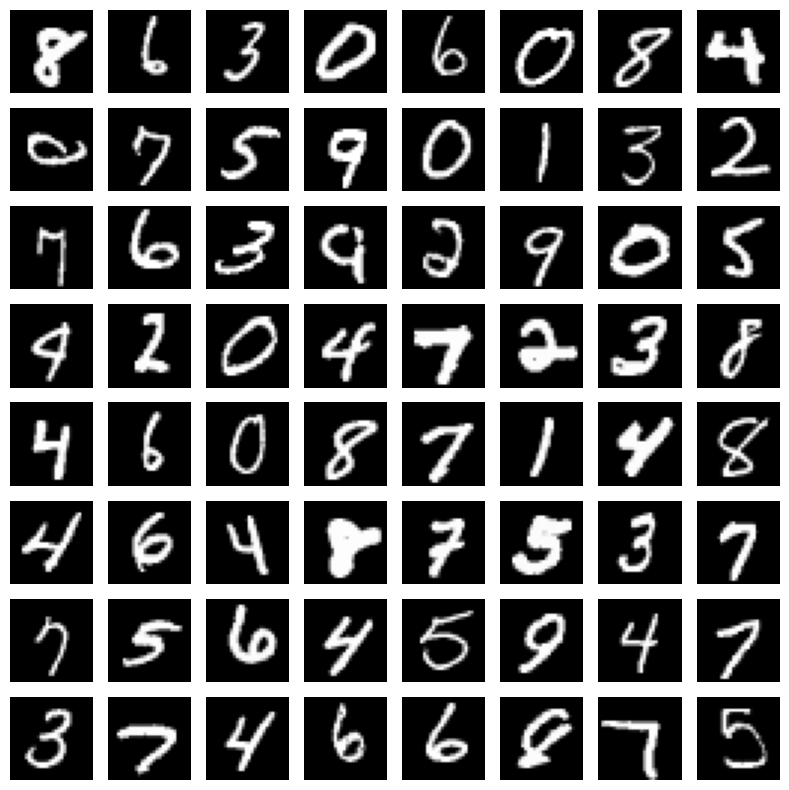

In [14]:
def show_images(images, title, nrow=8):
    images = images.detach().cpu()
    images = (images + 1) / 2
    n = min(images.size(0), nrow * nrow)
    fig, axes = plt.subplots(nrow, nrow, figsize=(nrow, nrow))
    for ax, img in zip(axes.flat, images[:n]):
        ax.imshow(img.squeeze(0), cmap='gray', vmin=0, vmax=1)
        ax.axis('off')
    for ax in axes.flat[n:]:
        ax.axis('off')
    #fig.suptitle(title)
    plt.tight_layout()
    plt.show()

real_batch, _ = next(iter(loader))
show_images(real_batch[:64], 'Amostras reais do MNIST')

### Arquitetura da rede GAN: DCGAN

O gerador recebe um vetor latente $z \sim \mathcal{N}(0, I)$ com dimensao 100 e produz uma imagem 1 x 28 x 28. A expansao espacial e feita por convolucoes transpostas. O discriminador recebe uma imagem 1 x 28 x 28 e retorna um logit real/falso.

In [15]:
LATENT_DIM = 100
FEATURES_G = 64
FEATURES_D = 64

class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, features=FEATURES_G):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, features * 4, 7, 1, 0, bias=False),
            nn.BatchNorm2d(features * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(features * 4, features * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(features * 2, 1, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z)

class Discriminator(nn.Module):
    def __init__(self, features=FEATURES_D):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, features, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(features, features * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(features * 2, 1, 7, 1, 0, bias=False),
        )

    def forward(self, x):
        return self.net(x).view(-1)

def weights_init(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)

G_test = Generator().to(device)
D_test = Discriminator().to(device)
z = torch.randn(4, LATENT_DIM, 1, 1, device=device)
assert G_test(z).shape == (4, 1, 28, 28)
assert D_test(G_test(z)).shape == (4,)
del G_test, D_test, z

### Metricas de qualidade

Para evitar depender de uma rede classificadora externa, as metricas sao calculadas sobre caracteristicas simples das imagens: cada imagem 28 x 28 e reduzida para 7 x 7 por average pooling e depois vetorizada.

FID-pixel: mede a distancia de Frechet entre duas gaussianas ajustadas as caracteristicas reais e geradas. Menor e melhor. Embora o FID original use features de uma rede Inception, aqui a adaptacao e adequada para comparar modelos no mesmo dominio MNIST, desde que a limitacao seja declarada.

MMD-RBF: mede a discrepancia entre duas distribuicoes por kernel gaussiano. Menor e melhor. Diferente do FID, nao assume explicitamente que as features seguem uma distribuicao gaussiana.

In [16]:
def image_features(images):
    images = (images.detach().float().cpu() + 1) / 2
    pooled = torch.nn.functional.avg_pool2d(images, kernel_size=4)
    return pooled.flatten(1).numpy()

def matrix_sqrt_psd(matrix):
    values, vectors = np.linalg.eigh(matrix)
    values = np.clip(values, 0, None)
    return (vectors * np.sqrt(values)) @ vectors.T

def fid_pixel(real_features, fake_features, eps=1e-6):
    mu_r = real_features.mean(axis=0)
    mu_f = fake_features.mean(axis=0)
    cov_r = np.cov(real_features, rowvar=False) + eps * np.eye(real_features.shape[1])
    cov_f = np.cov(fake_features, rowvar=False) + eps * np.eye(fake_features.shape[1])
    covmean = matrix_sqrt_psd(cov_r @ cov_f)
    score = np.sum((mu_r - mu_f) ** 2) + np.trace(cov_r + cov_f - 2 * covmean)
    return float(np.real(score))

def mmd_rbf(real_features, fake_features, max_items=512):
    real = torch.tensor(real_features[:max_items], dtype=torch.float32)
    fake = torch.tensor(fake_features[:max_items], dtype=torch.float32)
    combined = torch.cat([real, fake], dim=0)
    dists = torch.cdist(combined, combined).pow(2)
    sigma2 = torch.median(dists[dists > 0]).clamp_min(1e-6)

    k_rr = torch.exp(-torch.cdist(real, real).pow(2) / (2 * sigma2)).mean()
    k_ff = torch.exp(-torch.cdist(fake, fake).pow(2) / (2 * sigma2)).mean()
    k_rf = torch.exp(-torch.cdist(real, fake).pow(2) / (2 * sigma2)).mean()
    return float(k_rr + k_ff - 2 * k_rf)

@torch.no_grad()
def sample_fake(generator, n_images, batch_size=256):
    generator.eval()
    batches = []
    for start in range(0, n_images, batch_size):
        current = min(batch_size, n_images - start)
        z = torch.randn(current, LATENT_DIM, 1, 1, device=device)
        batches.append(generator(z).cpu())
    return torch.cat(batches, dim=0)

@torch.no_grad()
def collect_real_images(n_images):
    batches = []
    for real, _ in loader:
        batches.append(real)
        if sum(batch.size(0) for batch in batches) >= n_images:
            break
    return torch.cat(batches, dim=0)[:n_images]

EVAL_IMAGES = 1024
real_eval_images = collect_real_images(EVAL_IMAGES)
real_eval_features = image_features(real_eval_images)

### Treinamento e criterios de parada

Criterio 1: parar apos um numero fixo de epocas.

Criterio 2: calcular FID-pixel ao fim de cada epoca e interromper se ele nao melhorar por `patience` epocas apos um numero minimo de epocas. Esse criterio usa a ideia de que, depois de certo ponto, continuar o jogo adversarial pode nao melhorar a qualidade visual e pode ate levar a oscilacoes.

In [26]:
from collections import deque

LR = 2e-4
BETA1 = 0.5
BETA2 = 0.999
LABEL_REAL = 1.0
LABEL_FAKE = 0.0

def evaluate_generator(generator):
    fake_images = sample_fake(generator, EVAL_IMAGES)
    fake_features = image_features(fake_images)
    return {
        'fid_pixel': fid_pixel(real_eval_features, fake_features),
        'mmd_rbf': mmd_rbf(real_eval_features, fake_features),
    }

@torch.no_grad()
def compute_discriminator_accuracy(discriminator, generator, val_loader=None, num_fake_samples=256):
    """
    Calcula a acurácia do discriminador em distinguir real vs. falso.
    Se val_loader for fornecido, usa esse conjunto (held-out) para as imagens reais;
    caso contrário, usa um batch novo de imagens geradas + o loader de treino como fallback.
    """
    discriminator.eval()
    generator.eval()

    source_loader = val_loader if val_loader is not None else loader
    correct = 0
    total = 0

    real_batch, _ = next(iter(source_loader))
    real_batch = real_batch.to(device)
    logits_real = discriminator(real_batch)
    preds_real = (torch.sigmoid(logits_real) > 0.5).float()
    correct += (preds_real == LABEL_REAL).sum().item()
    total += real_batch.size(0)

    z = torch.randn(num_fake_samples, LATENT_DIM, 1, 1, device=device)
    fake_batch = generator(z)
    logits_fake = discriminator(fake_batch)
    preds_fake = (torch.sigmoid(logits_fake) > 0.5).float()
    correct += (preds_fake == LABEL_FAKE).sum().item()
    total += fake_batch.size(0)

    discriminator.train()
    generator.train()

    return correct / total


def train_gan(
    run_name, stop_rule, max_epochs, min_epochs=0, patience=5, min_delta=1e-3,
    acc_patience=5, acc_stability_delta=0.02, val_loader=None,
):
    torch.manual_seed(SEED)
    generator = Generator().to(device)
    discriminator = Discriminator().to(device)
    generator.apply(weights_init)
    discriminator.apply(weights_init)

    criterion = nn.BCEWithLogitsLoss()
    opt_g = torch.optim.Adam(generator.parameters(), lr=LR, betas=(BETA1, BETA2))
    opt_d = torch.optim.Adam(discriminator.parameters(), lr=LR, betas=(BETA1, BETA2))

    history = {'epoch': [], 'loss_g': [], 'loss_d': [], 'fid_pixel': [], 'mmd_rbf': [], 'lr_g': [], 'disc_acc': []}
    best_score = math.inf
    best_state = None
    bad_epochs = 0
    acc_window = deque(maxlen=acc_patience)
    fixed_noise = torch.randn(64, LATENT_DIM, 1, 1, device=device)

    for epoch in range(1, max_epochs + 1):
        generator.train()
        discriminator.train()
        loss_g_sum = 0.0
        loss_d_sum = 0.0

        for real_images, _ in loader:
            real_images = real_images.to(device)
            batch_size = real_images.size(0)
            real_labels = torch.full((batch_size,), LABEL_REAL, device=device)
            fake_labels = torch.full((batch_size,), LABEL_FAKE, device=device)

            opt_d.zero_grad(set_to_none=True)
            logits_real = discriminator(real_images)
            loss_d_real = criterion(logits_real, real_labels)
            z = torch.randn(batch_size, LATENT_DIM, 1, 1, device=device)
            fake_images = generator(z)
            logits_fake = discriminator(fake_images.detach())
            loss_d_fake = criterion(logits_fake, fake_labels)
            loss_d = loss_d_real + loss_d_fake
            loss_d.backward()
            opt_d.step()

            opt_g.zero_grad(set_to_none=True)
            logits_fake_for_g = discriminator(fake_images)
            loss_g = criterion(logits_fake_for_g, real_labels)
            loss_g.backward()
            opt_g.step()

            loss_g_sum += loss_g.item()
            loss_d_sum += loss_d.item()

        metrics = evaluate_generator(generator)
        disc_acc = compute_discriminator_accuracy(discriminator, generator, val_loader=val_loader)

        mean_loss_g = loss_g_sum / len(loader)
        mean_loss_d = loss_d_sum / len(loader)
        history['epoch'].append(epoch)
        history['loss_g'].append(mean_loss_g)
        history['loss_d'].append(mean_loss_d)
        history['fid_pixel'].append(metrics['fid_pixel'])
        history['mmd_rbf'].append(metrics['mmd_rbf'])
        history['lr_g'].append(opt_g.param_groups[0]['lr'])
        history['disc_acc'].append(disc_acc)

        print(
            f'{run_name} | epoch {epoch:03d} | '
            f'loss_D={mean_loss_d:.4f} | loss_G={mean_loss_g:.4f} | '
            f'FID-pixel={metrics["fid_pixel"]:.4f} | MMD={metrics["mmd_rbf"]:.6f} | '
            f'Disc-acc={disc_acc:.4f}'
        )

        if metrics['fid_pixel'] < best_score - min_delta:
            best_score = metrics['fid_pixel']
            best_state = deepcopy(generator.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1

        # --- critério de estabilidade da acurácia do discriminador ---
        acc_window.append(disc_acc)
        acc_is_stable = (
            len(acc_window) == acc_window.maxlen
            and (max(acc_window) - min(acc_window)) <= acc_stability_delta
        )

        if stop_rule == 'early_fid' and epoch >= min_epochs and bad_epochs >= patience:
            print(f'Parada antecipada em {epoch} epocas; melhor FID-pixel={best_score:.4f}.')
            break

        if stop_rule == 'disc_acc_stable' and epoch >= min_epochs and acc_is_stable:
            print(
                f'Parada antecipada em {epoch} epocas; acuracia do discriminador estavel '
                f'entre {min(acc_window):.4f} e {max(acc_window):.4f} '
                f'nas ultimas {acc_patience} epocas.'
            )
            break

    if best_state is not None:
        generator.load_state_dict(best_state)
    final_metrics = evaluate_generator(generator)
    samples = generator(fixed_noise).detach().cpu()
    return generator, history, final_metrics, samples

### Execucao dos dois experimentos

A celula abaixo treina dois modelos independentes com a mesma semente e os mesmos hiperparametros. Para uma execucao rapida, reduza `MAX_TRAIN_SAMPLES`, `FIXED_EPOCHS` e `EARLY_MAX_EPOCHS`. Para o relatorio final, recomenda-se usar todos os 60.000 exemplos.

In [35]:
FIXED_EPOCHS = 100
EARLY_MAX_EPOCHS = 100
EARLY_MIN_EPOCHS = 10
EARLY_PATIENCE = 5

In [36]:
G_fixed, hist_fixed, metrics_fixed, samples_fixed = train_gan(
    run_name='parada_fixa',
    stop_rule='fixed',
    max_epochs=FIXED_EPOCHS,
)

parada_fixa | epoch 001 | loss_D=0.6066 | loss_G=1.8096 | FID-pixel=0.2701 | MMD=0.008175 | Disc-acc=0.7578
parada_fixa | epoch 002 | loss_D=0.5390 | loss_G=1.9197 | FID-pixel=0.2122 | MMD=0.009272 | Disc-acc=0.8724
parada_fixa | epoch 003 | loss_D=0.6823 | loss_G=1.7310 | FID-pixel=0.2092 | MMD=0.004588 | Disc-acc=0.8776
parada_fixa | epoch 004 | loss_D=0.7981 | loss_G=1.6272 | FID-pixel=0.2664 | MMD=0.011999 | Disc-acc=0.6927
parada_fixa | epoch 005 | loss_D=0.7948 | loss_G=1.5540 | FID-pixel=0.2023 | MMD=0.004303 | Disc-acc=0.3333
parada_fixa | epoch 006 | loss_D=0.8640 | loss_G=1.5074 | FID-pixel=0.1992 | MMD=0.003819 | Disc-acc=0.8073
parada_fixa | epoch 007 | loss_D=0.8099 | loss_G=1.5517 | FID-pixel=0.2113 | MMD=0.006519 | Disc-acc=0.8490
parada_fixa | epoch 008 | loss_D=0.8596 | loss_G=1.5152 | FID-pixel=0.1662 | MMD=0.003122 | Disc-acc=0.6849
parada_fixa | epoch 009 | loss_D=0.8182 | loss_G=1.5857 | FID-pixel=0.1377 | MMD=0.002636 | Disc-acc=0.4479
parada_fixa | epoch 010 | lo

In [37]:
G_early, hist_early, metrics_early, samples_early = train_gan(
    run_name='parada_antecipada_fid',
    stop_rule='early_fid',
    max_epochs=EARLY_MAX_EPOCHS,
    min_epochs=EARLY_MIN_EPOCHS,
    patience=EARLY_PATIENCE,
)

parada_antecipada_fid | epoch 001 | loss_D=0.6153 | loss_G=1.8098 | FID-pixel=0.2820 | MMD=0.009159 | Disc-acc=0.7786
parada_antecipada_fid | epoch 002 | loss_D=0.5293 | loss_G=1.9150 | FID-pixel=0.2105 | MMD=0.009003 | Disc-acc=0.8698
parada_antecipada_fid | epoch 003 | loss_D=0.7513 | loss_G=1.6800 | FID-pixel=0.1986 | MMD=0.004877 | Disc-acc=0.7708
parada_antecipada_fid | epoch 004 | loss_D=0.7891 | loss_G=1.5884 | FID-pixel=0.3652 | MMD=0.027856 | Disc-acc=0.7135
parada_antecipada_fid | epoch 005 | loss_D=0.8153 | loss_G=1.5198 | FID-pixel=0.1792 | MMD=0.004124 | Disc-acc=0.5078
parada_antecipada_fid | epoch 006 | loss_D=0.7861 | loss_G=1.5820 | FID-pixel=0.1502 | MMD=0.003632 | Disc-acc=0.8073
parada_antecipada_fid | epoch 007 | loss_D=0.7991 | loss_G=1.5937 | FID-pixel=0.1618 | MMD=0.005445 | Disc-acc=0.6745
parada_antecipada_fid | epoch 008 | loss_D=0.8115 | loss_G=1.5835 | FID-pixel=0.1749 | MMD=0.003569 | Disc-acc=0.8177
parada_antecipada_fid | epoch 009 | loss_D=0.8086 | loss

In [38]:
DISC_ACC_MAX_EPOCHS = 100
DISC_ACC_MIN_EPOCHS = 10
DISC_ACC_PATIENCE = 10        # numero de epocas consecutivas para considerar "estavel"
DISC_ACC_STABILITY_DELTA = 0.1  # variacao maxima permitida dentro da janela

G_disc_acc, hist_disc_acc, metrics_disc_acc, samples_disc_acc = train_gan(
    run_name='parada_disc_acc_estavel',
    stop_rule='disc_acc_stable',
    max_epochs=DISC_ACC_MAX_EPOCHS,
    min_epochs=DISC_ACC_MIN_EPOCHS,
    acc_patience=DISC_ACC_PATIENCE,
    acc_stability_delta=DISC_ACC_STABILITY_DELTA,
    val_loader=val_loader,
)

parada_disc_acc_estavel | epoch 001 | loss_D=0.6119 | loss_G=1.8068 | FID-pixel=0.2651 | MMD=0.008280 | Disc-acc=0.7422
parada_disc_acc_estavel | epoch 002 | loss_D=0.5229 | loss_G=1.9251 | FID-pixel=0.1943 | MMD=0.009535 | Disc-acc=0.7995
parada_disc_acc_estavel | epoch 003 | loss_D=0.7184 | loss_G=1.7436 | FID-pixel=0.2038 | MMD=0.004526 | Disc-acc=0.8516
parada_disc_acc_estavel | epoch 004 | loss_D=0.7659 | loss_G=1.6203 | FID-pixel=0.1935 | MMD=0.004914 | Disc-acc=0.6979
parada_disc_acc_estavel | epoch 005 | loss_D=0.7906 | loss_G=1.5810 | FID-pixel=0.1590 | MMD=0.004352 | Disc-acc=0.7578
parada_disc_acc_estavel | epoch 006 | loss_D=0.8323 | loss_G=1.5728 | FID-pixel=0.2137 | MMD=0.007916 | Disc-acc=0.7891
parada_disc_acc_estavel | epoch 007 | loss_D=0.8182 | loss_G=1.5471 | FID-pixel=0.1770 | MMD=0.004076 | Disc-acc=0.7630
parada_disc_acc_estavel | epoch 008 | loss_D=0.8362 | loss_G=1.5369 | FID-pixel=0.1813 | MMD=0.005353 | Disc-acc=0.7135
parada_disc_acc_estavel | epoch 009 | lo

### Graficos e comparacao

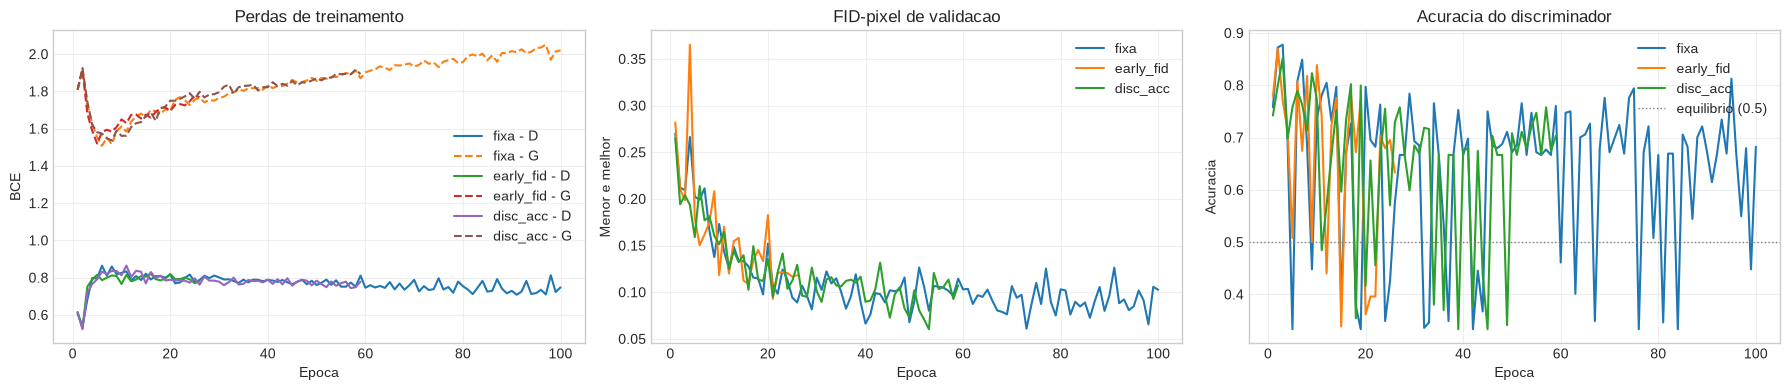

In [39]:
def plot_history(histories):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    for name, hist in histories.items():
        axes[0].plot(hist['epoch'], hist['loss_d'], label=f'{name} - D')
        axes[0].plot(hist['epoch'], hist['loss_g'], linestyle='--', label=f'{name} - G')
        axes[1].plot(hist['epoch'], hist['fid_pixel'], label=name)
        if 'disc_acc' in hist:
            axes[2].plot(hist['epoch'], hist['disc_acc'], label=name)

    axes[0].set_title('Perdas de treinamento')
    axes[0].set_xlabel('Epoca')
    axes[0].set_ylabel('BCE')

    axes[1].set_title('FID-pixel de validacao')
    axes[1].set_xlabel('Epoca')
    axes[1].set_ylabel('Menor e melhor')

    axes[2].set_title('Acuracia do discriminador')
    axes[2].set_xlabel('Epoca')
    axes[2].set_ylabel('Acuracia')
    axes[2].axhline(0.5, color='gray', linestyle=':', linewidth=1, label='equilibrio (0.5)')

    for ax in axes:
        ax.grid(True, alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

plot_history({'fixa': hist_fixed, 'early_fid': hist_early, 'disc_acc': hist_disc_acc})

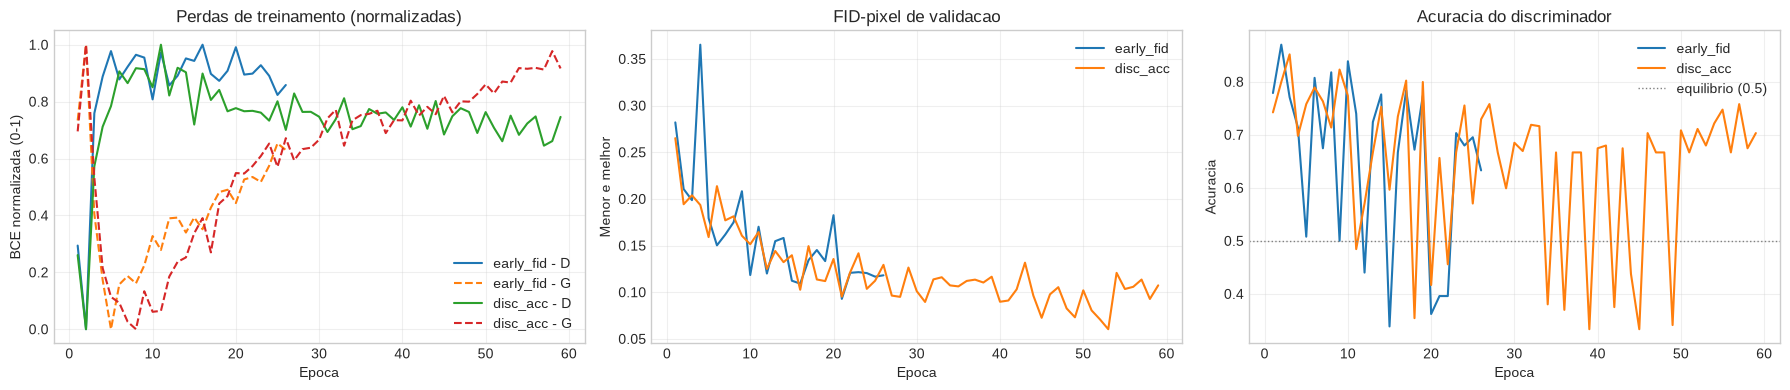

In [43]:
def normalize(values):
    values = np.array(values, dtype=float)
    v_min, v_max = values.min(), values.max()
    if v_max - v_min < 1e-12:  # evita divisao por zero se a serie for constante
        return np.zeros_like(values)
    return (values - v_min) / (v_max - v_min)


def plot_history(histories):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    for name, hist in histories.items():
        axes[0].plot(hist['epoch'], normalize(hist['loss_d']), label=f'{name} - D')
        axes[0].plot(hist['epoch'], normalize(hist['loss_g']), linestyle='--', label=f'{name} - G')
        axes[1].plot(hist['epoch'], hist['fid_pixel'], label=name)
        if 'disc_acc' in hist:
            axes[2].plot(hist['epoch'], hist['disc_acc'], label=name)

    axes[0].set_title('Perdas de treinamento (normalizadas)')
    axes[0].set_xlabel('Epoca')
    axes[0].set_ylabel('BCE normalizada (0-1)')

    axes[1].set_title('FID-pixel de validacao')
    axes[1].set_xlabel('Epoca')
    axes[1].set_ylabel('Menor e melhor')

    axes[2].set_title('Acuracia do discriminador')
    axes[2].set_xlabel('Epoca')
    axes[2].set_ylabel('Acuracia')
    axes[2].axhline(0.5, color='gray', linestyle=':', linewidth=1, label='equilibrio (0.5)')

    for ax in axes:
        ax.grid(True, alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

#plot_history({'fixa': hist_fixed, 'early_fid': hist_early, 'disc_acc': hist_disc_acc})7
plot_history({'early_fid': hist_early, 'disc_acc': hist_disc_acc})

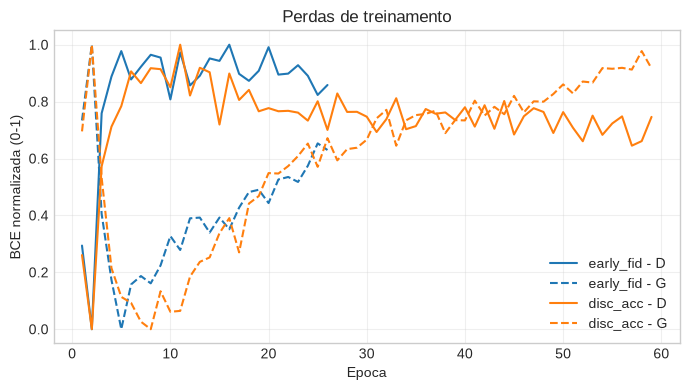

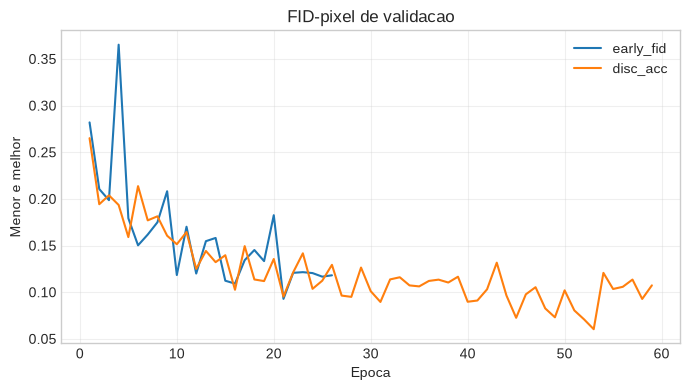

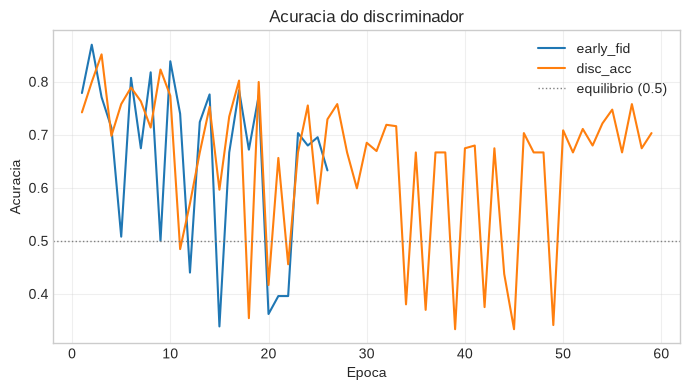

In [44]:
RUN_COLORS = {
    'fixa': 'tab:green',
    'early_fid': 'tab:blue',
    'disc_acc': 'tab:orange',
}

def get_color(name, fallback_idx):
    return RUN_COLORS.get(name, plt.cm.tab10(fallback_idx % 10))


def plot_losses(histories, normalize_losses=True):
    fig, ax = plt.subplots(figsize=(7, 4))
    for i, (name, hist) in enumerate(histories.items()):
        color = get_color(name, i)
        loss_d = normalize(hist['loss_d']) if normalize_losses else hist['loss_d']
        loss_g = normalize(hist['loss_g']) if normalize_losses else hist['loss_g']
        ax.plot(hist['epoch'], loss_d, color=color, linestyle='-', label=f'{name} - D')
        ax.plot(hist['epoch'], loss_g, color=color, linestyle='--', label=f'{name} - G')

    ylabel = 'BCE normalizada (0-1)' if normalize_losses else 'BCE'
    ax.set_title('Perdas de treinamento')
    ax.set_xlabel('Epoca')
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_fid(histories):
    fig, ax = plt.subplots(figsize=(7, 4))
    for i, (name, hist) in enumerate(histories.items()):
        color = get_color(name, i)
        ax.plot(hist['epoch'], hist['fid_pixel'], color=color, label=name)

    ax.set_title('FID-pixel de validacao')
    ax.set_xlabel('Epoca')
    ax.set_ylabel('Menor e melhor')
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_disc_accuracy(histories):
    fig, ax = plt.subplots(figsize=(7, 4))
    for i, (name, hist) in enumerate(histories.items()):
        if 'disc_acc' not in hist:
            continue
        color = get_color(name, i)
        ax.plot(hist['epoch'], hist['disc_acc'], color=color, label=name)

    ax.axhline(0.5, color='gray', linestyle=':', linewidth=1, label='equilibrio (0.5)')
    ax.set_title('Acuracia do discriminador')
    ax.set_xlabel('Epoca')
    ax.set_ylabel('Acuracia')
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


histories = {'early_fid': hist_early, 'disc_acc': hist_disc_acc}

plot_losses(histories)
plot_fid(histories)
plot_disc_accuracy(histories)

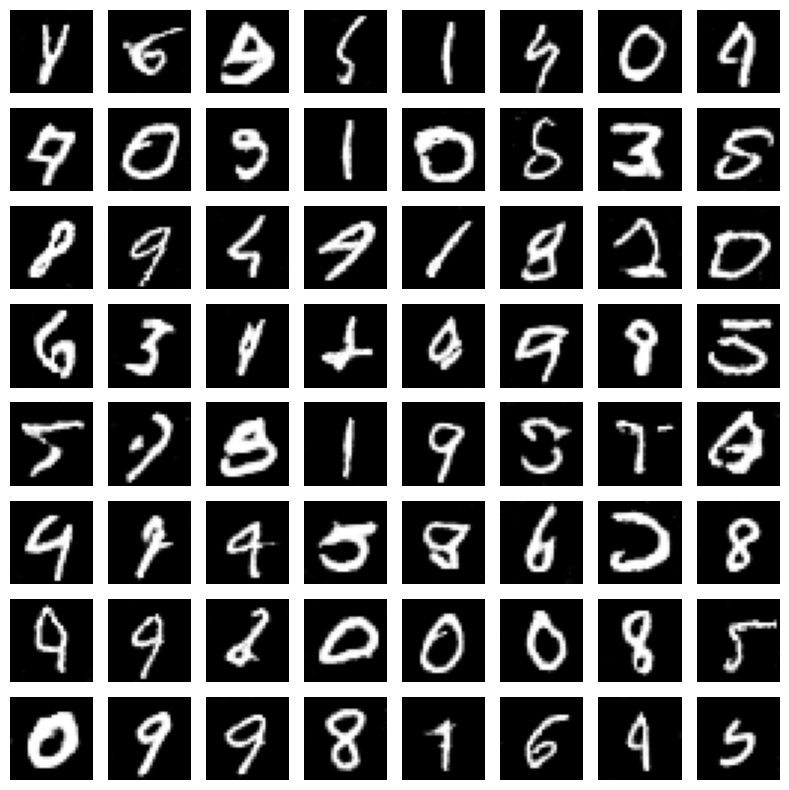

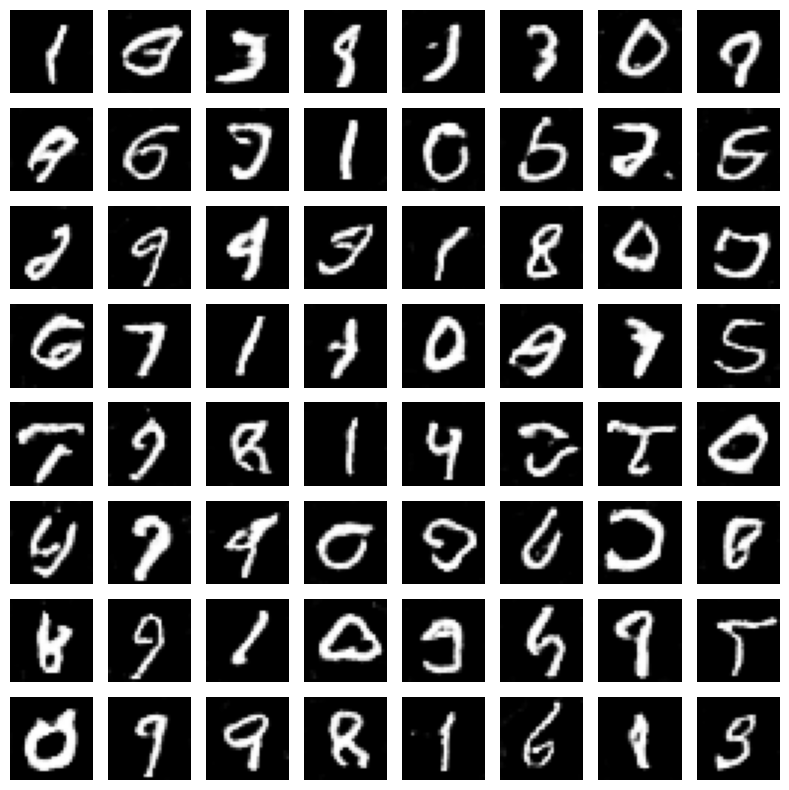

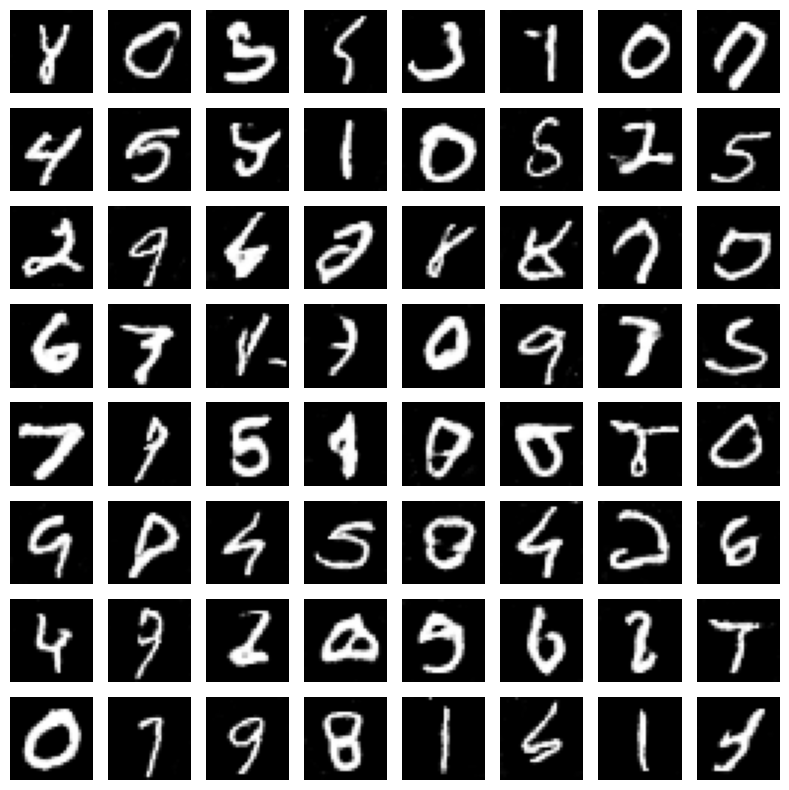

In [40]:
show_images(samples_fixed, 'Amostras geradas - criterio de parada fixa')
show_images(samples_early, 'Amostras geradas - criterio de parada antecipada por FID-pixel')
show_images(samples_disc_acc, 'Amostras geradas - criterio de parada antecipada por Acurácia do discriminador')

In [41]:
summary = {
    'parada_fixa': {
        'epocas_treinadas': len(hist_fixed['epoch']),
        **metrics_fixed,
    },
    'parada_antecipada_fid': {
        'epocas_treinadas': len(hist_early['epoch']),
        **metrics_early,
    },
    'parada_antecipada_disc_acc': {
        'epocas_treinadas': len(hist_disc_acc['epoch']),
        **metrics_disc_acc,
    },
}
summary

{'parada_fixa': {'epocas_treinadas': 100,
  'fid_pixel': 0.1075426763445584,
  'mmd_rbf': 0.0021260976791381836},
 'parada_antecipada_fid': {'epocas_treinadas': 26,
  'fid_pixel': 0.11638519818285428,
  'mmd_rbf': 0.00379180908203125},
 'parada_antecipada_disc_acc': {'epocas_treinadas': 59,
  'fid_pixel': 0.07265944894775553,
  'mmd_rbf': 0.001424551010131836}}

## Discussao esperada

Depois de executar o notebook, compare os valores finais de `fid_pixel` e `mmd_rbf` no dicionario `summary`. O melhor modelo deve apresentar valores menores nas duas metricas e amostras visualmente mais parecidas com digitos do MNIST.

A parada por numero fixo de epocas e simples e reprodutivel, mas pode desperdiçar treinamento depois que a qualidade estabiliza ou pode parar antes da convergencia. A parada antecipada baseada em FID-pixel adapta o numero de epocas ao comportamento observado da GAN. Como GANs podem oscilar, esse criterio tende a escolher o melhor gerador visto durante o treinamento, nao necessariamente o gerador da ultima epoca.

A evolucao das perdas deve ser interpretada com cuidado: em GANs, perdas menores nao significam automaticamente imagens melhores, porque gerador e discriminador estao em competicao. Por isso as curvas de qualidade, como FID-pixel e MMD, sao mais informativas para comparar os dois criterios de parada.

A curva de taxa de aprendizagem e constante neste experimento, pois nao foi usado scheduler. Isso isola o efeito do criterio de parada. Se fosse usado decaimento de learning rate, seria necessario discutir separadamente o efeito do scheduler na estabilidade do treinamento.